In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
rulfd001 = pd.read_csv('CMAPSSData/RUL_FD001.txt', sep='\s+', header=None)
rulfd002 = pd.read_csv('CMAPSSData/RUL_FD002.txt', sep='\s+', header=None)
rulfd003 = pd.read_csv('CMAPSSData/RUL_FD003.txt', sep='\s+', header=None)
rulfd004 = pd.read_csv('CMAPSSData/RUL_FD004.txt', sep='\s+', header=None)

rul = pd.concat([rulfd001, rulfd002, rulfd003, rulfd004])


trainfd001 = pd.read_csv('CMAPSSData/train_FD001.txt', sep='\s+', header=None)
trainfd002 = pd.read_csv('CMAPSSData/train_FD002.txt', sep='\s+', header=None)
trainfd003 = pd.read_csv('CMAPSSData/train_FD003.txt', sep='\s+', header=None)
trainfd004 = pd.read_csv('CMAPSSData/train_FD004.txt', sep='\s+', header=None)

train = pd.concat([trainfd001, trainfd002, trainfd003, trainfd004])


testfd001 = pd.read_csv('CMAPSSData/test_FD001.txt', sep='\s+', header=None)
testfd002 = pd.read_csv('CMAPSSData/test_FD002.txt', sep='\s+', header=None)
testfd003 = pd.read_csv('CMAPSSData/test_FD003.txt', sep='\s+', header=None)
testfd004 = pd.read_csv('CMAPSSData/test_FD004.txt', sep='\s+', header=None)

test = pd.concat([testfd001, testfd002, testfd003, testfd004])

rul = rulfd001
train = trainfd001
test = testfd001

print(
    f'{train.shape}\n{test.shape}\n{rul.shape}'
)

(20631, 26)
(13096, 26)
(100, 1)


In [4]:
# rul = pd.read_csv('CMAPSSData/RUL_FD001.txt', sep='\s+', header=None)
# train = pd.read_csv('CMAPSSData/train_FD001.txt', sep='\s+', header=None)
# test = pd.read_csv('CMAPSSData/test_FD001.txt', sep='\s+', header=None)

# print(
#     f'{train.shape}\n{test.shape}\n{rul.shape}'
# )


In [5]:
train.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [6]:
print(f"Number of Engines: {len(train[0].unique())}")

Number of Engines: 100


In [7]:
cycle_counts = train.groupby(0)[1].count()
print(cycle_counts.values)

[192 287 179 189 269 188 259 150 201 222 240 170 163 180 207 209 276 195
 158 234 195 202 168 147 230 199 156 165 163 194 234 191 200 195 181 158
 170 194 128 188 216 196 207 192 158 256 214 231 215 198 213 213 195 257
 193 275 137 147 231 172 185 180 174 283 153 202 313 199 362 137 208 213
 213 166 229 210 154 231 199 185 240 214 293 267 188 278 178 213 217 154
 135 341 155 258 283 336 202 156 185 200]


In [8]:
# # generate target RUL based on number of cycles observed
# '''
# Inputs:
# - data_length: int
#     - the number of cycles for a given engine
# - early_rul: int
#     - int which is assigned as the target RUL for all early cycles of an engine
#     - if early_rul is not none, then the first data_length - early_rul cycles are assigned an RUL value of early_rul
#     - the rest of the RUL target values are assigned linearly such that each successive cycle reduces the RUL by 1
# Output:
# - target_array of ints
#     - the value of each index describes the number of cycles remaining as of that index
# '''
# def process_targets(data_length, early_rul=None):

#     if early_rul == None:
#         return np.arange(data_length - 1, -1, -1)
#     else:
#         early_rul_duration = data_length - early_rul

#         if early_rul_duration <= 0:
#             return np.arange(data_length - 1, -1, -1)
        
#         target_array = np.append(early_rul * np.ones(shape=early_rul_duration), np.arange(early_rul, -1, -1))
#         return target_array


In [10]:
test.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [11]:
len(test[0].unique())

100

In [12]:
test.groupby(0)[1].count().values

array([ 31,  49, 126, 106,  98, 105, 160, 166,  55, 192,  83, 217, 195,
        46,  76, 113, 165, 133, 135, 184, 148,  39, 130, 186,  48,  76,
       140, 158, 171, 143, 196, 145,  50, 203, 198, 126, 121, 125,  37,
       133, 123, 156, 172,  54, 152, 146,  73,  78, 303,  74, 144, 189,
       164, 121, 113, 136, 160, 176,  94, 147, 159, 232, 155, 168,  71,
       147,  71, 187,  54, 152,  68, 131, 112, 137,  88, 205, 162,  72,
       101, 133, 213, 162,  73, 172,  34, 110,  56,  68, 177, 146, 234,
       150, 244, 133,  89,  97, 134, 121,  97, 198])

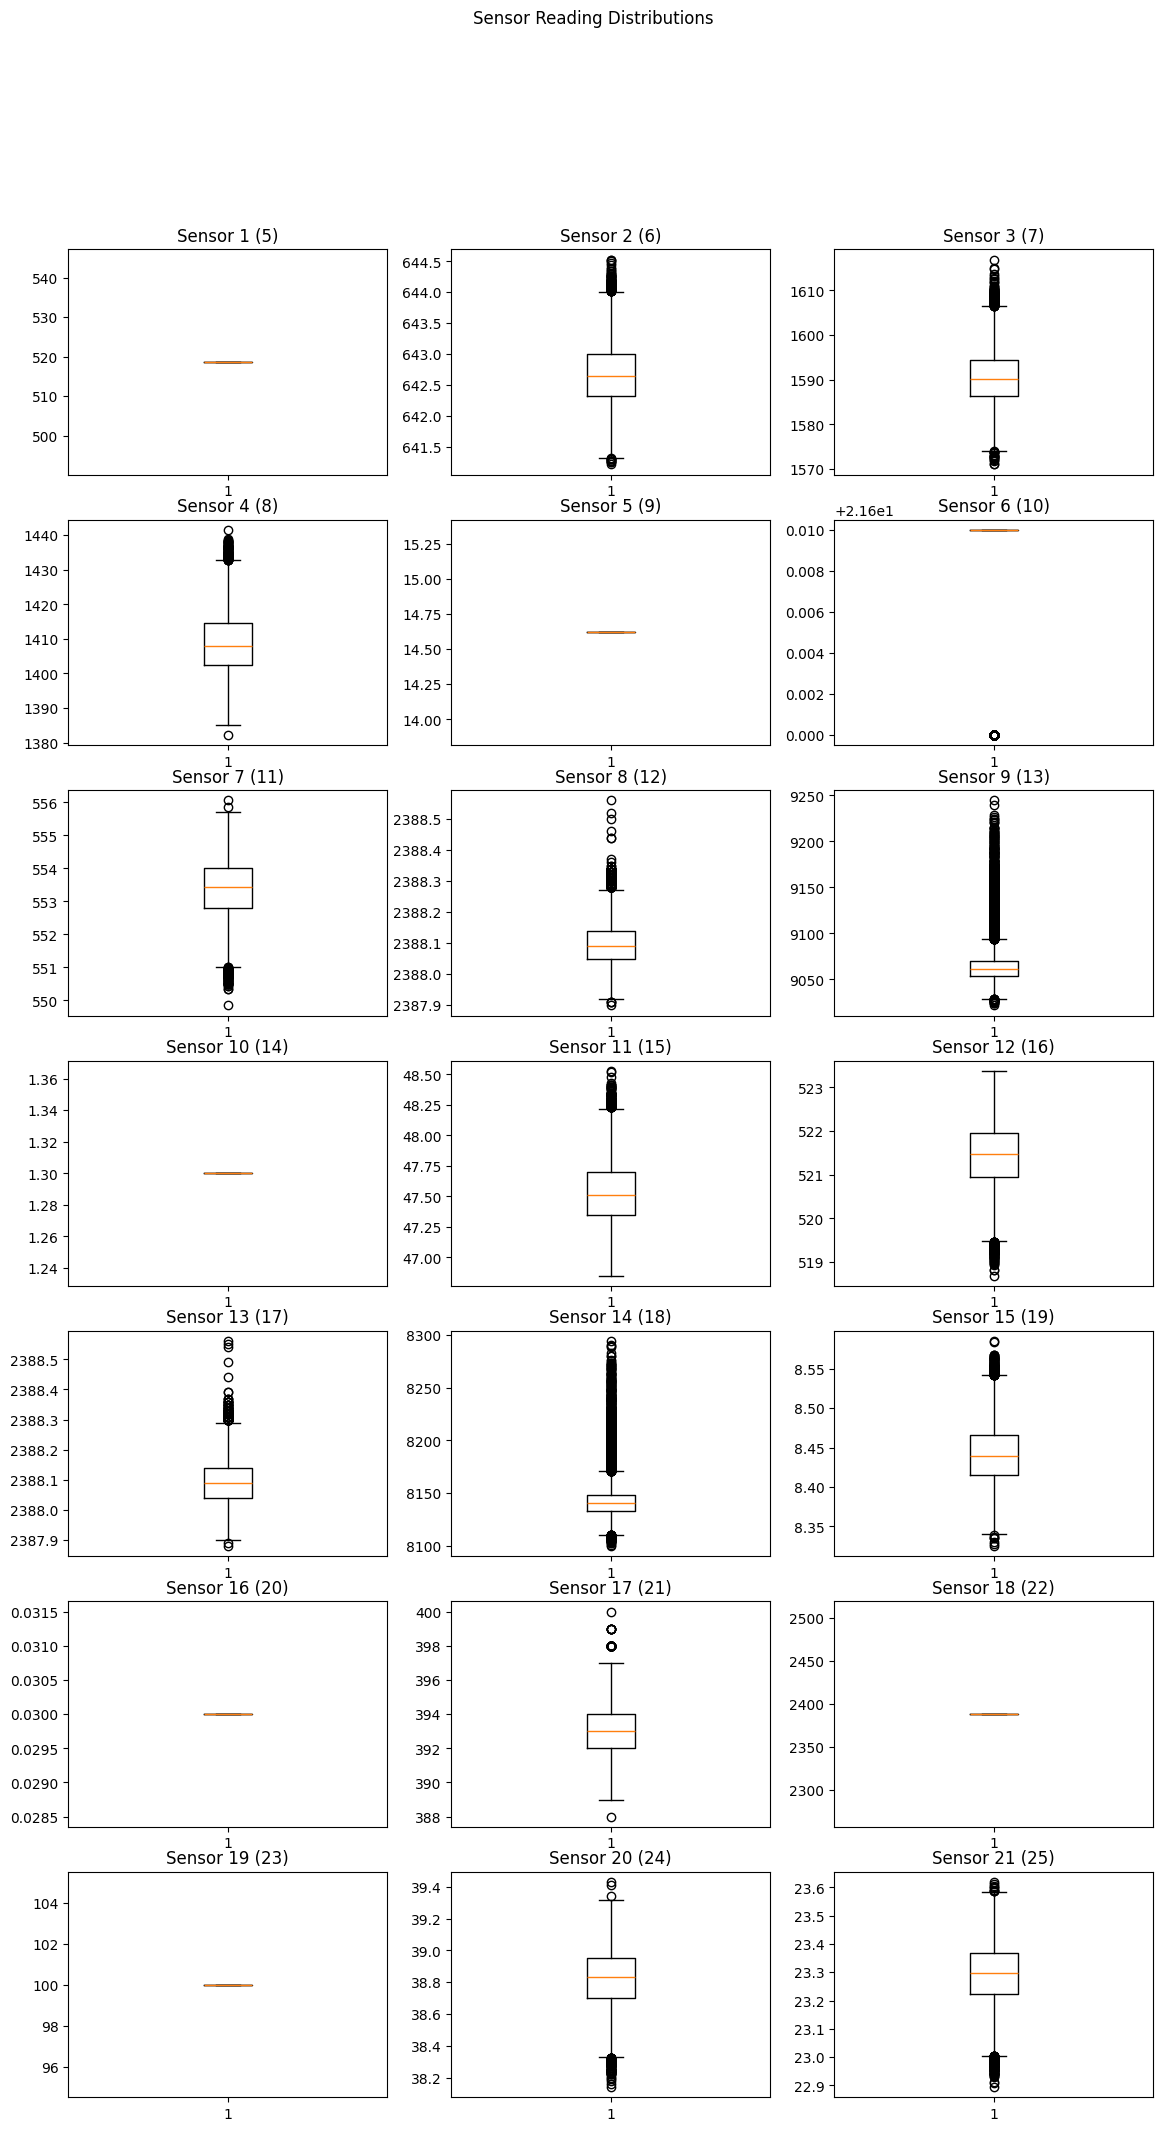

In [13]:
fig, ax = plt.subplots(7,3, figsize=(14, 24))


fig.suptitle('Sensor Reading Distributions')
for row in range(7):
    for col in range(3):
        sensor = (row) * 3 + col + 5
        ax[row, col].boxplot(train[sensor])

        ax[row,col].set_title(f'Sensor {sensor - 4} ({sensor})')

In [14]:
# remove sensors with nearly constant readings
columns_to_remove = [5, 9, 10, 14, 20, 22, 23]

train = train.drop(columns=columns_to_remove)
test = test.drop(columns=columns_to_remove)

train.head(10)

,0,1,2,3,4,6,7,8,11,12,13,15,16,17,18,19,21,24,25
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044
5,1,6,-0.0043,-0.0001,100.0,642.10,1584.47,1398.37,554.67,2388.02,9049.68,47.16,521.68,2388.03,8132.85,8.4108,391,38.98,23.3669
6,1,7,0.0010,0.0001,100.0,642.48,1592.32,1397.77,554.34,2388.02,9059.13,47.36,522.32,2388.03,8132.32,8.3974,392,39.10,23.3774
7,1,8,-0.0034,0.0003,100.0,642.56,1582.96,1400.97,553.85,2388.00,9040.80,47.24,522.47,2388.03,8131.07,8.4076,391,38.97,23.3106
8,1,9,0.0008,0.0001,100.0,642.12,1590.98,1394.80,553.69,2388.05,9046.46,47.29,521.79,2388.05,8125.69,8.3728,392,39.05,23.4066
9,1,10,-0.0033,0.0001,100.0,641.71,1591.24,1400.46,553.59,2388.05,9051.70,47.03,521.79,2388.06,8129.38,8.4286,393,38.95,23.4694


In [15]:
# explicitly name engine, cycle columns for training dataset
train = train.rename(columns={0 : 'engine', 1 : 'cycle'})
train.head(10)

,engine,cycle,2,3,4,6,7,8,11,12,13,15,16,17,18,19,21,24,25
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044
5,1,6,-0.0043,-0.0001,100.0,642.10,1584.47,1398.37,554.67,2388.02,9049.68,47.16,521.68,2388.03,8132.85,8.4108,391,38.98,23.3669
6,1,7,0.0010,0.0001,100.0,642.48,1592.32,1397.77,554.34,2388.02,9059.13,47.36,522.32,2388.03,8132.32,8.3974,392,39.10,23.3774
7,1,8,-0.0034,0.0003,100.0,642.56,1582.96,1400.97,553.85,2388.00,9040.80,47.24,522.47,2388.03,8131.07,8.4076,391,38.97,23.3106
8,1,9,0.0008,0.0001,100.0,642.12,1590.98,1394.80,553.69,2388.05,9046.46,47.29,521.79,2388.05,8125.69,8.3728,392,39.05,23.4066
9,1,10,-0.0033,0.0001,100.0,641.71,1591.24,1400.46,553.59,2388.05,9051.70,47.03,521.79,2388.06,8129.38,8.4286,393,38.95,23.4694


In [16]:
# explicitly name engine, cycle columns for testing dataset
test = test.rename(columns={0 : 'engine', 1 : 'cycle'})
test.head(10)

,engine,cycle,2,3,4,6,7,8,11,12,13,15,16,17,18,19,21,24,25
0,1,1,0.0023,0.0003,100.0,643.02,1585.29,1398.21,553.90,2388.04,9050.17,47.20,521.72,2388.03,8125.55,8.4052,392,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,641.71,1588.45,1395.42,554.85,2388.01,9054.42,47.50,522.16,2388.06,8139.62,8.3803,393,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,642.46,1586.94,1401.34,554.11,2388.05,9056.96,47.50,521.97,2388.03,8130.10,8.4441,393,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,642.44,1584.12,1406.42,554.07,2388.03,9045.29,47.28,521.38,2388.05,8132.90,8.3917,391,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,642.51,1587.19,1401.92,554.16,2388.01,9044.55,47.31,522.15,2388.03,8129.54,8.4031,390,38.99,23.4130
5,1,6,0.0012,0.0003,100.0,642.11,1579.12,1395.13,554.22,2388.00,9050.96,47.26,521.92,2388.08,8127.46,8.4238,392,38.91,23.3467
6,1,7,-0.0000,0.0002,100.0,642.11,1583.34,1404.84,553.89,2388.05,9051.39,47.31,522.01,2388.06,8134.97,8.3914,391,38.85,23.3952
7,1,8,0.0006,-0.0000,100.0,642.54,1580.89,1400.89,553.59,2388.05,9052.86,47.21,522.09,2388.06,8125.93,8.4213,393,39.05,23.3224
8,1,9,-0.0036,0.0000,100.0,641.88,1593.29,1412.28,554.49,2388.06,9048.55,47.37,522.03,2388.05,8134.15,8.4353,391,39.10,23.4521
9,1,10,-0.0025,-0.0001,100.0,642.07,1585.25,1398.64,554.28,2388.04,9051.95,47.14,522.00,2388.06,8134.08,8.4093,391,38.87,23.3820


In [17]:

# RUL column is set to 125 for the first num_cycles - 125 cycles of an engine, and decreases by one for each successive cycle thereafter
train['rul'] = np.minimum(125, train.groupby('engine')['cycle'].transform('max') - train['cycle'])
train.head(10)

,engine,cycle,2,3,4,6,7,8,11,12,13,15,16,17,18,19,21,24,25,rul
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,125
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,125
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,125
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,125
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,125
5,1,6,-0.0043,-0.0001,100.0,642.10,1584.47,1398.37,554.67,2388.02,9049.68,47.16,521.68,2388.03,8132.85,8.4108,391,38.98,23.3669,125
6,1,7,0.0010,0.0001,100.0,642.48,1592.32,1397.77,554.34,2388.02,9059.13,47.36,522.32,2388.03,8132.32,8.3974,392,39.10,23.3774,125
7,1,8,-0.0034,0.0003,100.0,642.56,1582.96,1400.97,553.85,2388.00,9040.80,47.24,522.47,2388.03,8131.07,8.4076,391,38.97,23.3106,125
8,1,9,0.0008,0.0001,100.0,642.12,1590.98,1394.80,553.69,2388.05,9046.46,47.29,521.79,2388.05,8125.69,8.3728,392,39.05,23.4066,125
9,1,10,-0.0033,0.0001,100.0,641.71,1591.24,1400.46,553.59,2388.05,9051.70,47.03,521.79,2388.06,8129.38,8.4286,393,38.95,23.4694,125


In [18]:
# define feature columns
feature_cols = [2, 3, 4, 6, 7, 8, 11, 12, 13, 15, 16, 17, 18, 19, 21, 24, 25]

In [19]:
def create_windows(df, feature_cols, window_length=30):

    X, y = [], []

    for engine_id, engine_df in df.groupby('engine'):

        engine_df = engine_df.sort_values('cycle')

        features = engine_df[feature_cols].to_numpy()

        if 'rul' in engine_df.columns:
            rul = engine_df['rul'].to_numpy()

        for end in range(window_length, len(engine_df) + 1):

            X.append(features[end - window_length : end])
            if 'rul' in engine_df.columns:
                y.append(rul[end - 1])

    return np.array(X), np.array(y)

In [20]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train,
        groups=train["engine"]
    )
)

train_df = train.iloc[train_idx]
val_df = train.iloc[val_idx]

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_df[feature_cols] = scaler.fit_transform(
    train_df[feature_cols]
)

val_df[feature_cols] = scaler.transform(
    val_df[feature_cols]
)

test[feature_cols] = scaler.transform(
    test[feature_cols]
)



/var/folders/_v/z7ywlj2x7ll58r_cj2_yq2k00000gn/T/ipykernel_69971/1750333501.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df[feature_cols] = scaler.fit_transform(
/var/folders/_v/z7ywlj2x7ll58r_cj2_yq2k00000gn/T/ipykernel_69971/1750333501.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val_df[feature_cols] = scaler.transform(


In [23]:
test.to_csv('test.csv')
rul.to_csv('rul.csv')

In [22]:
X_train, y_train = create_windows(train_df, feature_cols, window_length=30)

X_val, y_val = create_windows(val_df, feature_cols, window_length=30)

In [23]:
print(X_train.shape, y_train.shape)

(14241, 30, 17) (14241,)


In [24]:
%pip install --no-cache-dir tensorflow


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [25]:
import tensorflow as tf

print(tf.__version__)
print(tf.__file__)

2.21.0
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tensorflow/__init__.py


In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [59]:



class LastWindowScore(tf.keras.callbacks.Callback):

    def __init__(self, val_df, feature_cols, n_cuts=5, window=30, seed=0):
        super().__init__()
        rng = np.random.default_rng(seed)
        X, y = [], []

        for _, engine in val_df.groupby('engine'):
            engine = engine.sort_values('cycle')
            features, rul = engine[feature_cols].to_numpy(), engine['rul'].to_numpy()

            for _ in range(n_cuts):
                end = rng.integers(window, len(engine) + 1)
                begin = end - window
                X.append(features[begin:end])
                y.append(rul[end-1])

        self.X, self.y = np.array(X), np.array(y)

    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.X, verbose=0).flatten()
        d = pred - self.y
        score = np.mean(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))
        logs['val_last_window'] = score
        print(f' - val_last_window: {score:.4f}')

In [60]:
def nasa_loss(y_true, y_pred):
    # Flatten both to 1D so (n, 1) and (n,) can't broadcast into an n x n grid
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])

    d = y_pred - y_true  # positive = predicted too late (overestimate)

    penalties = tf.where(
        d < 0,
        tf.exp(-d / 13.0) - 1.0,  # early prediction, milder penalty
        tf.exp(d / 10.0) - 1.0    # late prediction, harsher penalty
    )

    return tf.reduce_mean(penalties)

In [64]:
from tensorflow.keras.layers import Input
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

def run_experiment(
    X_train, y_train, X_val, y_val,
    val_df,
    feature_cols,
    units=(64, 32),
    dropout=0.1,
    dense_units=32,
    learning_rate=0.001,
    loss='nasa',
    batch_size=128,
    epochs=50,
    seed=42
):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    model = Sequential()
    model.add(Input(shape=X_train.shape[1:]))

    for i, n_units in enumerate(units):
        model.add(
            LSTM(
                n_units,
                return_sequences=(i < len(units) - 1)
            )
        )

        if dropout > 0:
            model.add(Dropout(dropout))

    if dense_units:
        model.add(Dense(dense_units, activation='relu'))

    model.add(Dense(1))

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss=nasa_loss,
        metrics=['mae']
    )

    last_window = LastWindowScore(val_df, feature_cols)

    early_stopping = EarlyStopping(
        patience=3,
        monitor='val_last_window',
        mode='min',
        restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[last_window, early_stopping],
        verbose=1
    )

    pred = model.predict(X_val, verbose=0).flatten()

    result = {
        "units": str(units),
        "dropout": dropout,
        "dense_units": dense_units,
        "learning_rate": learning_rate,
        "loss": loss,
        "batch_size": batch_size,
        "best_epoch": (
            int(pd.Series(history.history["val_loss"]).idxmin()) + 1
        ),
        "val_mae": mean_absolute_error(y_val, pred),
        "val_rmse": root_mean_squared_error(y_val, pred),
        "best_val_loss": min(history.history["val_loss"]),
        'best_val_last_window' : min(history.history['val_last_window'])
    }

    return model, result, history
 

In [65]:
experiments = [
    {
        "name": "baseline",
        "units": (64, 32),
        "dropout": 0.2,
        "dense_units": 32,
        "loss": "mse"
    },
    {
        "name": "single_lstm_64",
        "units": (64,),
        "dropout": 0.2,
        "dense_units": 32,
        "loss": "mse"
    },
    {
        "name": "single_lstm_32",
        "units": (32,),
        "dropout": 0.2,
        "dense_units": 32,
        "loss": "mse"
    },
    {
        "name": "larger_lstm",
        "units": (128, 64),
        "dropout": 0.2,
        "dense_units": 32,
        "loss": "mse"
    },
    {
        "name": "less_dropout",
        "units": (64, 32),
        "dropout": 0.1,
        "dense_units": 32,
        "loss": "mse"
    },
    {
        "name": "huber_loss",
        "units": (64, 32),
        "dropout": 0.2,
        "dense_units": 32,
        "loss": tf.keras.losses.Huber(delta=10.0)
    }
]

In [66]:
results = []
models = {}
histories = {}

for exp in experiments:

    name = exp['name']
    config = {k:v for k,v in exp.items() if k != 'name'}

    model, result, history = run_experiment(
        X_train, y_train, X_val, y_val, val_df, feature_cols,
        **config
    )

    result['name'] = name
    results.append(result)
    models[name] = model
    histories[name] = history

pd.DataFrame(results).to_csv("rul_experiments.csv", index=False)

Epoch 1/50
111/112 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 2783.1892 - mae: 72.1991 - val_last_window: 729.9684
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - loss: 2779.1394 - mae: 72.1882 - val_loss: 927.1155 - val_mae: 61.3274 - val_last_window: 729.9684
Epoch 2/50
111/112 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 513.2070 - mae: 55.2912 - val_last_window: 182.8322
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 512.6582 - mae: 55.2895 - val_loss: 231.8885 - val_mae: 48.2654 - val_last_window: 182.8322
Epoch 3/50
110/112 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 163.5974 - mae: 44.2629 - val_last_window: 74.3530
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 162.9208 - mae: 44.2127 - val_loss: 93.7866 - val_mae: 38.9860 - val_last_window: 74.3530
Epoch 4/50
110/112 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 77.1289 - mae: 37.5534 - val_last_window: 39.5450
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 76.8875 - mae: 37.5233 - val_loss: 49.6299 - val_mae: 33.9899 - val_last_wi

In [71]:
model = models['single_lstm_64']
model.save('single_lstm_64.keras')

## Calibrate the uncertainty band

The app shows a 90% range from Monte Carlo (MC) dropout. Raw MC dropout ranges are usually too narrow, so here we measure, on the **validation engines**, how much the band must be widened for 90% of true RULs to fall inside it. The factor is saved to `calibration.json` and loaded by `app.py`.

Re-run this cell whenever the model is retrained.

In [ ]:
import json
from util import mc_dropout_predict

TARGET_COVERAGE = 0.90
N_SAMPLES = 50

calib_model = tf.keras.models.load_model(
    'single_lstm_64.keras', custom_objects={'nasa_loss': nasa_loss}
)

# Every sliding window of every validation engine (y = capped RUL at the window's end)
X_cal, y_cal = create_windows(val_df, feature_cols, window_length=30)
band = mc_dropout_predict(calib_model, X_cal, n_samples=N_SAMPLES, interval=TARGET_COVERAGE)

center = band['mc_mean'].to_numpy()
upper_half = np.maximum(band['mc_upper'].to_numpy() - center, 1e-6)
lower_half = np.maximum(center - band['mc_lower'].to_numpy(), 1e-6)

# How many half-widths away from the band's center each true RUL landed
scores = np.where(
    y_cal >= center,
    (y_cal - center) / upper_half,
    (center - y_cal) / lower_half,
)

# Smallest scale factor that covers TARGET_COVERAGE of the windows
# (the (n + 1) correction is the standard split-conformal adjustment)
n = len(scores)
level = min(1.0, np.ceil((n + 1) * TARGET_COVERAGE) / n)
interval_scale = float(np.quantile(scores, level, method='higher'))

raw_width = np.median(band['mc_upper'] - band['mc_lower'])
print(f'Validation windows:       {n} from {val_df["engine"].nunique()} engines')
print(f'Raw band coverage:        {np.mean(scores <= 1):.1%}  (median width {raw_width:.1f} cycles)')
print(f'Scale factor:             {interval_scale:.2f}')
print(f'Calibrated coverage:      {np.mean(scores <= interval_scale):.1%}  '
      f'(median width {interval_scale * raw_width:.1f} cycles)')

with open('calibration.json', 'w') as f:
    json.dump({
        'interval': TARGET_COVERAGE,
        'n_samples': N_SAMPLES,
        'interval_scale': interval_scale,
        'raw_coverage': float(np.mean(scores <= 1)),
        'n_windows': int(n),
    }, f, indent=2)

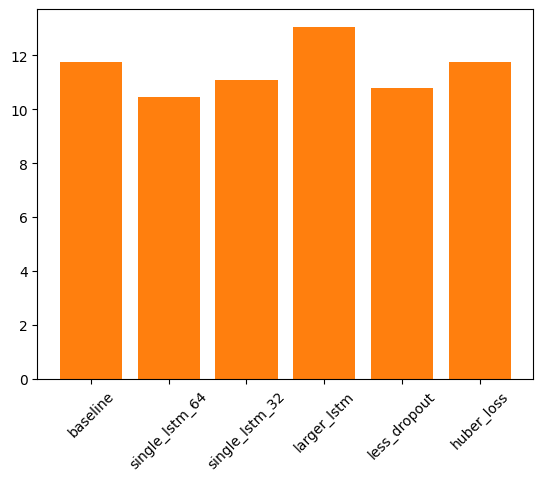

In [70]:
results = pd.read_csv('rul_experiments.csv')

plt.bar(results['name'], results['best_val_last_window'])
plt.bar(results['name'], results['val_mae'])
plt.tick_params(
    axis='x',
    rotation=45
)
plt.show()

In [ ]:
X_test, _ = create_windows(test, feature_cols, window_length=30)

In [ ]:
model = models['single_lstm_64']
predictions = model.predict(X_test).flatten()

last_predictions = []
start = 0

for n in windows_per_engine:
    last_predictions.append(predictions[start + n - 1])
    start += n

last_predictions = np.array(last_predictions)

print(last_predictions.shape)  # (100,)

319/319 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
(100,)


In [ ]:
last_predictions

array([110.90606 , 115.615364,  56.475952,  88.5039  , 102.85752 ,
        96.04585 ,  92.952095,  97.65089 , 115.22724 ,  89.34103 ,
        69.36303 ,  91.907036,  78.45761 , 104.41567 , 100.95668 ,
       102.87928 ,  40.89434 ,  35.536964,  87.94627 ,  14.712263,
        70.6554  , 116.71868 , 116.601166,  23.993872, 100.34692 ,
       109.47224 ,  88.84209 , 105.35504 ,  92.076614,  93.5224  ,
         9.8806  ,  49.574932, 100.40162 ,   9.213834,  10.366253,
        17.739304,  30.968164,  49.702805, 116.39472 ,  22.268139,
        31.83055 ,  15.619476,  61.922314, 108.819405,  96.31663 ,
        33.18718 , 110.250145,  97.04432 ,  16.416304,  92.21018 ,
       108.65937 ,  30.285769,  29.15547 , 111.82467 , 108.72636 ,
        12.383974, 105.683105,  45.884964, 105.292534, 107.67901 ,
        23.91936 ,  42.52789 ,  88.37773 ,  24.916265, 116.97475 ,
        14.738367, 112.69121 ,  12.3522  , 113.12614 , 101.06241 ,
       106.622795,  59.437485,  99.27746 , 100.21562 , 100.672

In [ ]:
rul[rul[0] > 125] = 125
rul

,0
0,112
1,98
2,69
3,82
4,91
...,...
95,125
96,82
97,59
98,117


In [ ]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


y_test = rul[0].to_numpy()

for name, model in models.items():
    predictions = model.predict(X_test).flatten()

    last_predictions = []
    start = 0

    for n in windows_per_engine:
        last_predictions.append(predictions[start + n - 1])
        start += n

    last_predictions = np.array(last_predictions)
    print(name)
    print(f'RMSE: {root_mean_squared_error(y_test, last_predictions):.3f}')
    print(f'MAE: {mean_absolute_error(y_test, last_predictions):.3f}')
    print(f'R^2: {r2_score(y_test, last_predictions):.3f}')
    print(f'NASA Score: {nasa_loss(np.array(y_test), last_predictions):.3f}')

319/319 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
baseline
RMSE: 13.392
MAE: 10.230
R^2: 0.888
NASA Score: 2.432
319/319 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
single_lstm_64
RMSE: 14.260
MAE: 10.504
R^2: 0.873
NASA Score: 3.953
319/319 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
single_lstm_32
RMSE: 14.126
MAE: 9.861
R^2: 0.876
NASA Score: 3.739
319/319 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
larger_lstm
RMSE: 13.841
MAE: 10.420
R^2: 0.881
NASA Score: 2.524
319/319 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
less_dropout
RMSE: 12.895
MAE: 9.207
R^2: 0.896
NASA Score: 2.867
319/319 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
huber_loss
RMSE: 13.392
MAE: 10.230
R^2: 0.888
NASA Score: 2.432


In [ ]:
np.array(rul)

array([[112],
       [ 98],
       [ 69],
       [ 82],
       [ 91],
       [ 93],
       [ 91],
       [ 95],
       [111],
       [ 96],
       [ 97],
       [124],
       [ 95],
       [107],
       [ 83],
       [ 84],
       [ 50],
       [ 28],
       [ 87],
       [ 16],
       [ 57],
       [111],
       [113],
       [ 20],
       [145],
       [119],
       [ 66],
       [ 97],
       [ 90],
       [115],
       [  8],
       [ 48],
       [106],
       [  7],
       [ 11],
       [ 19],
       [ 21],
       [ 50],
       [142],
       [ 28],
       [ 18],
       [ 10],
       [ 59],
       [109],
       [114],
       [ 47],
       [135],
       [ 92],
       [ 21],
       [ 79],
       [114],
       [ 29],
       [ 26],
       [ 97],
       [137],
       [ 15],
       [103],
       [ 37],
       [114],
       [100],
       [ 21],
       [ 54],
       [ 72],
       [ 28],
       [128],
       [ 14],
       [ 77],
       [  8],
       [121],
       [ 94],
       [118],
      

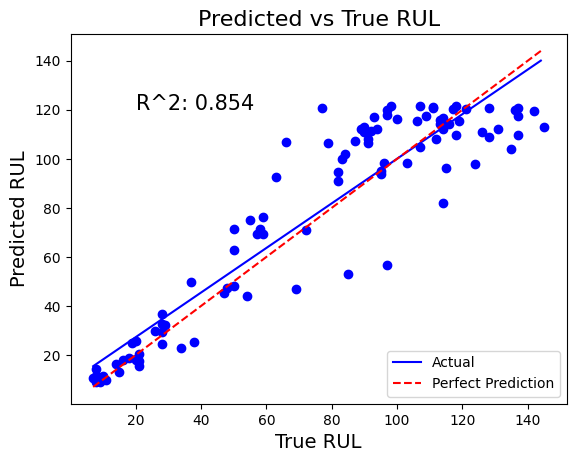

In [ ]:
plt.scatter(rul, last_predictions, color='blue')
x = np.arange(np.min(rul), np.max(rul), 1)
m, b = np.polyfit(np.array(rul).flatten(), last_predictions, 1)
plt.plot(x, m * x + b, color='blue', label='Actual')
plt.plot(x, x, color='red', linestyle='--', label='Perfect Prediction')

plt.xlabel('True RUL', fontsize=14)
plt.ylabel('Predicted RUL', fontsize=14)
plt.title('Predicted vs True RUL', fontsize=16)
plt.text(20, 120, f'R^2: {r2_score(rul, last_predictions):.3f}', fontsize=15)
plt.legend(loc='lower right')
plt.show()

Text(0, 0.5, 'Residual')

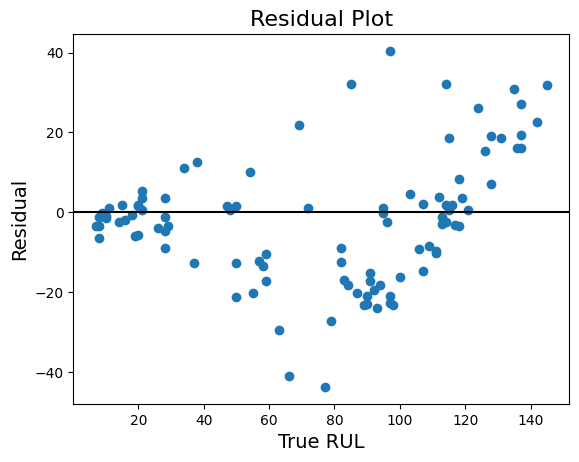

In [ ]:
residuals = np.array(rul).flatten() - last_predictions
plt.scatter(rul, residuals)
plt.axhline(y=0, color='black')

plt.title('Residual Plot', fontsize=16)
plt.xlabel('True RUL', fontsize=14)
plt.ylabel('Residual', fontsize=14)

In [ ]:
rul

,0
0,112
1,98
2,69
3,82
4,91
...,...
95,137
96,82
97,59
98,117


In [ ]:
results = pd.DataFrame({
    'true_rul': np.asarray(rul[0]),
    'predicted_rul': np.asarray(last_predictions)
})

results['error'] = (
    results['predicted_rul'] - results['true_rul']
)
results['absolute_error'] = results['error'].abs()

results['rul_range'] = pd.cut(
    results['true_rul'],
    bins=[-1, 20, 50, 100, 125, np.inf],
    labels=['0–20', '21–50', '51–100', '101–125', '>125']
)

print(
    results.groupby('rul_range', observed=False)
    .agg(
        count=('error', 'size'),
        MAE=('absolute_error', 'mean'),
        mean_error=('error', 'mean')
    )
)

           count        MAE  mean_error
rul_range                              
0–20          16   2.488095    1.698358
21–50         17   6.430204    1.666612
51–100        34  18.995035   12.720748
101–125       22   7.716401   -1.736282
>125          11  20.398576  -20.398576
